# Preliminary data exploration

The file \src\data_extraction\extract_cities.py analyses the raw dataset by loading the original csv files into temporary DuckDB tables. These are then filtered for specific cities (defined inside extract_cities.py) and the corresponding compressed parquet files are built.

In order to inspect what the files contain let's first define the working path.

In [1]:
from pathlib import Path

cwd = Path.cwd()
for folder in (cwd, *cwd.parents):
    if (folder / "src" / "data_extraction" / "extract_cities.py").is_file():
        PROJECT_ROOT = folder
        break
else:
    raise RuntimeError("Start Jupyter from the CityFlow folder or one of its subfolders.")

For each city we have the following files:

1) **cities** is single-row df containing : city id, name, coordinates (latitude and longitude), timezone, country and return_to_official_only (True = bikes can only be returned to official dock stations, False = bikes can be returned everywhere in designated zones)
2) **station_status** is a df containing : station_id, time, total numb of bikes, booked bikes, bikes available to rent, free racks, free special racks, maintenance status
3) **stations** is a df containing : id (equivalent to station_id), city_id (identical for each row), name, app_number, **terminal_type (not sure what this represents**), place_type, # of bike_racks, # of special_racks, rack_locks and coordinates (latitude and longitude)
4) **trips** is a df containing : bike_id, city_id (identical for each row), time_start, coordinates_start (latitude and longitude), coordinates_end (latitude and longitude), station_id_start, station_id_end, battery_start, battery_end, duration (seconds), distance (meters)

In [2]:
import duckdb

path = PROJECT_ROOT / "data" / "heidelberg" / "station_status.parquet"
duckdb.read_parquet(str(path)).limit(5).df()

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
0,681922,1.662022e+09,8,0,8,0,0,False
1,121357,1.662023e+09,7,0,7,1,0,False
2,681922,1.662023e+09,7,0,7,1,0,False
3,121354,1.662023e+09,8,0,8,0,0,False
4,1250591,1.662023e+09,23,0,23,0,0,False


Each parquet file has the following lenght. 

**NB :** for Heidelberg and Bergamo, the lenght of station_status is roughly twice the length of trips, because most trips start and end in a official docking station.

In [3]:
import pandas as pd

cities = ["heidelberg", "karlsruhe", "bergamo"]
datasets = ("cities", "station_status", "stations", "trips")
data_dir = PROJECT_ROOT / "data"

counts_by_city: dict[str, dict[str, int]] = {
    city: {
        name: len(duckdb.read_parquet(str(data_dir / city / f"{name}.parquet")))
        for name in datasets
    }
    for city in cities
}

pd.DataFrame.from_dict(counts_by_city, orient="index")

,cities,station_status,stations,trips
heidelberg,1,639976,50,346211
karlsruhe,1,392711,51,883185
bergamo,1,198214,71,104730


**Initially, I would focus on a city where return_to_official_only=True. This way the position of available bikes should be well-defined at any moment.**

**Idea :** we could make a classification model that tells you whether a specific journey is possible in a fixed time (e.g. 2 hours from now). Based on start and end dock station coordinates, we should predict the probability that at least 2 bikes are available in station_start 2 hours from now, and the probability that at least 2 racks are free in station_end 2 hours + travel time from now. The avg travel time between two stations can be computed from trips.parquet.

**Update :** turns out that the number of available racks does not pose a limit in the number of bikes that can be officially returned there!

## Inspecting trips dataset

**Check the return_to_official policy**

For cities where return_to_official_only is True, we would expect that each trip starts and ends in official dock stations. In practice, we find:
- Heidelberg : 12.9% (return_to_official_only = True)
- Bergamo :    12.9% (return_to_official_only = True)
- Karlsruhe :  97.1% (return_to_official_only = False) 

In [4]:
import sys

sys.path.insert(0, str(PROJECT_ROOT))
from src.inspection.trips import count_trips_missing_station_ids

city_dir = PROJECT_ROOT / "data" / "karlsruhe"
trips_path = city_dir / "trips.parquet"

count_trips_missing_station_ids(city_dir) / duckdb.execute('SELECT COUNT(*) FROM read_parquet(?)', [str(trips_path)]).fetchall()[0][0]

0.970818118514241

The percentage, of failed return_to_official for Heidelberg and Bergamo are suspisciously close. Let's analyse if this problem arises uniformly during the year or whether they occour at specific dates.

In [5]:
from src.inspection.trips import days_with_missing_station_ids

city_dir = PROJECT_ROOT / "data" / "heidelberg"
trips_path = city_dir / "trips.parquet"

days_with_missing_station_ids(city_dir, n=100)

([datetime.date(2022, 8, 27),
  datetime.date(2022, 8, 29),
  datetime.date(2022, 9, 2),
  datetime.date(2022, 9, 3),
  datetime.date(2022, 9, 4),
  datetime.date(2022, 9, 6),
  datetime.date(2022, 9, 7),
  datetime.date(2022, 9, 8),
  datetime.date(2022, 9, 9),
  datetime.date(2022, 9, 12),
  datetime.date(2022, 9, 15),
  datetime.date(2022, 9, 20),
  datetime.date(2022, 9, 21),
  datetime.date(2022, 9, 22),
  datetime.date(2022, 9, 23),
  datetime.date(2022, 9, 30),
  datetime.date(2022, 10, 4),
  datetime.date(2022, 10, 5),
  datetime.date(2022, 10, 6),
  datetime.date(2022, 10, 7),
  datetime.date(2022, 10, 8),
  datetime.date(2022, 10, 9),
  datetime.date(2022, 10, 10),
  datetime.date(2022, 10, 11),
  datetime.date(2022, 10, 12),
  datetime.date(2022, 10, 13),
  datetime.date(2022, 10, 14),
  datetime.date(2022, 10, 15),
  datetime.date(2022, 10, 16),
  datetime.date(2022, 10, 17),
  datetime.date(2022, 10, 18),
  datetime.date(2022, 10, 19),
  datetime.date(2022, 10, 20),
  date

It turns out that most days (>90%) contain trips where either the start or end dock station is not specified. This can be further inspected by looking at the percentage distribution of trips per day over the entire year. 

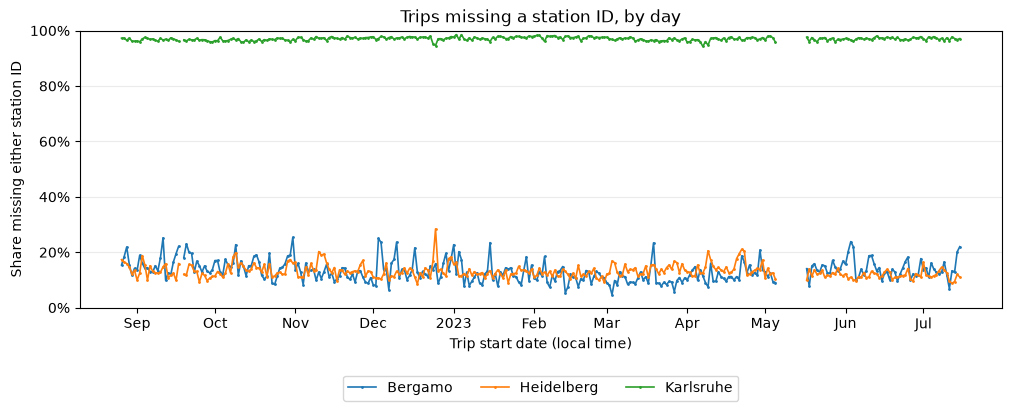

In [6]:
from src.inspection.trips import plot_daily_missing_station_id_share

ax = plot_daily_missing_station_id_share(PROJECT_ROOT / "data")

### Conclusion

It turns out that out of the trips that are missing either station ID, most of them are actually missing the end station. I think this is related to trips where the bike was not properly returned either because of app/bike malfunction, or voluntarily by the user. Either way, this is probably not allowed by the app and a fine is applied to cover the costs of moving the bikes to an appropriate station.

If this is the case, in our model we should consider a user that wants to start and end their trip in an official dock station to not encounter such additional fines.

**Option :** we could clean the trips dataset by excluding all the unofficial trips that didn't start or end in an official dock station.

**NB:** there are also trips that end outside of Heidelberg, in nearby cities. These trips should also be excluded

## Inspecting station_status dataset

Lets start with a simple and important test to check that for every station status update we find that $$\rm{bikes = booked\_bikes + bikes\_available\_to\_rent}$$

In [7]:
from src.inspection.station_status import station_status_mismatch_ratio

city_dir = PROJECT_ROOT / "data" / "karlsruhe"
trips_path = city_dir / "trips.parquet"

station_status_mismatch_ratio(city_dir)

0.011331488040823914

Most station updates follow this rule. The percentage of problematic updates is:
- Heidelberg = 0.0125%
- Bergamo = 0.054%
- Karlsruhe = 1.13%

At least for Heidelberg and Bergamo (where return_to_official policy applies) the number of problematic station update is very low.

We have essentially 2 types of dock stations: either with bike_racks=0, or bike_racks>0. Therefore, we can compute the following tests
1. If bike_racks=0, compute the average number of bikes and the corresponding std
2. If bike_racks>0, compute the percentage of situation where : $\rm{bike\_racks \neq bikes + free\_racks}$

In [8]:
from src.inspection.station_status import station_rack_summary

city_dir = PROJECT_ROOT / "data" / "heidelberg"
trips_path = city_dir / "trips.parquet"

station_rack_summary(city_dir).head(50)

,station_id,station_name,bike_racks,rack_mismatch_ratio,mean_bikes,std_bikes
0,121354,S-Bahnhof Weststadt/Südstadt,8,0.428629,6.648659,5.257366
1,121355,Neuenheimer Feld – Zoo,10,0.506443,10.717201,7.584100
2,121357,Neuenheimer Feld – Jahnstraße,8,0.186782,3.765828,3.247181
3,121359,Neuenheim – Kußmaulstraße,6,0.289708,4.036952,3.396479
4,121361,Altstadt – Universitätsplatz,10,0.560715,11.479234,8.255796
5,121363,Altstadt – Stadthalle,10,0.289895,6.993975,5.597902
6,121368,Neuenheim – Neckarwiese,14,0.447239,14.489330,15.224540
7,121377,Hauptbahnhof Nord,16,0.508935,16.018441,9.726871
8,339517,Rohrbach – Markt,10,0.520864,12.196586,9.178666
9,339519,S-Bahnhof Schlierbach/Ziegelhausen,6,0.438434,6.857805,5.519613


## Inspect time evolution

In [9]:
# On average, a station in Heidelberg changes its status this many times per hour assuming a coverage period of one year:

counts_by_city['heidelberg']['station_status'] / counts_by_city['heidelberg']['stations'] / 365 / 24

1.4611324200913243

We can analyse the coverage over the analysed period by looking at the station_status changes per docking station over custom delta time (e.g. deltaT = 1, 8, 24)

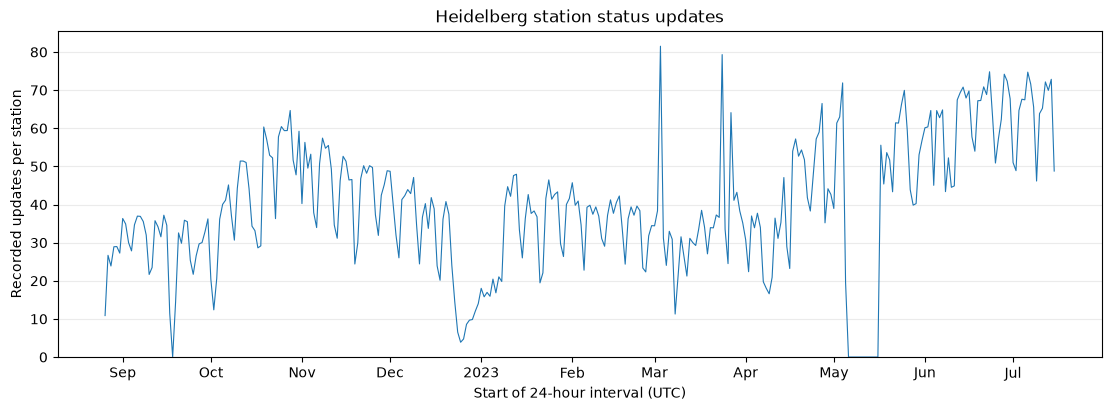

In [20]:
from src.inspection.time_analysis import (
    hourly_station_status_changes,
    plot_hourly_station_status_changes,
)

city_dir = PROJECT_ROOT / "data" / "heidelberg"

hourly = hourly_station_status_changes(city_dir, deltaT=24)
ax = plot_hourly_station_status_changes(city_dir, deltaT=24)

# Persistence Model

We defined a simple persistence model where the classification is based on the last known station_status. In particular, we classify the station as
- at_risk = 1 if bikes_available_to_rent =< 2
- at_risk = 0 if bikes_available_to_rent > 2
The persistence model assumes that there is no change over time. This is a useful benchmark to test our future ML model.

In [22]:
from src.modelling.persistance import predict_persistence

city_dir = PROJECT_ROOT / "data" / "heidelberg"
at_risk = predict_persistence(city_dir, station_id=121357, time=1661525401)
at_risk

0

In order to evaluate the performance of this simple model and establish a benchmark, we first need to divide our datasets in train (70%), evaluation (15%) and test (15%) subsets. This must be done by dividing our original datasets into chronological order, since we are dealing with timeseries data.

In [ ]:
from src.data_extraction.split_data import split_station_status_by_time

city_dir = PROJECT_ROOT / "data" / "heidelberg"
train, evaluation, test = split_station_status_by_time(city_dir)